# Step 1: download our code from GitHub.
# The token comes from Colab's Secrets (key icon on the left), so it is never written in the notebook.

In [2]:
import os
import subprocess
import sys
from pathlib import Path

from google.colab import userdata

BRANCH = "alliane"  # the branch the results are pushed to
ROOT = Path("/content/dqn-atari")  # where the code is downloaded inside Colab

token = userdata.get("GITHUB_TOKEN")
repo_url = f"https://{token}@github.com/H-levison/dqn-atari.git"

if not ROOT.exists():
    # capture_output=True hides git's output, so an error can never show the token
    result = subprocess.run(["git", "clone", "-b", BRANCH, repo_url, str(ROOT)], capture_output=True)
    if result.returncode != 0:
        raise RuntimeError("Could not download the code. Check the GITHUB_TOKEN secret.")

# Commits made from Colab are saved under my name
subprocess.run(["git", "config", "user.name", "Alliane Umutoniwase"], cwd=ROOT, check=True)
subprocess.run(["git", "config", "user.email", "a.umutoniwa1@alustudent.com"], cwd=ROOT, check=True)

print("Code downloaded to", ROOT)

Code downloaded to /content/dqn-atari


# Step 2: install the packages with uv (group rule: uv, never pip).

In [3]:
subprocess.run("curl -LsSf https://astral.sh/uv/install.sh | sh", shell=True, check=True)
os.environ["PATH"] = str(Path.home() / ".local/bin") + os.pathsep + os.environ["PATH"]

# Installs everything listed in pyproject.toml. Takes a few minutes the first time.
subprocess.run(["uv", "sync"], cwd=ROOT, check=True)

# This must print True. If it prints False, go to Runtime > Change runtime type > T4 GPU.
check_gpu = "import torch; print('GPU available:', torch.cuda.is_available())"
subprocess.run(["uv", "run", "python", "-c", check_gpu], cwd=ROOT, check=True)

CompletedProcess(args=['uv', 'run', 'python', '-c', "import torch; print('GPU available:', torch.cuda.is_available())"], returncode=0)

# Step 3: two helper functions that every experiment below uses.

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(ROOT))
from plot_results import plot_training  # the plotting function from plot_results.py


def save_to_github(name):
    # Colab deletes its files when it disconnects, so push each finished run to GitHub.
    folder = f"experiments/Alliane/{name}"
    subprocess.run(["git", "add", folder], cwd=ROOT, check=True)
    subprocess.run(["git", "commit", "-m", f"Add Alliane {name} results"], cwd=ROOT, check=True)
    subprocess.run(["git", "pull", "--rebase", "origin", BRANCH], cwd=ROOT, capture_output=True)
    result = subprocess.run(["git", "push", "origin", BRANCH], cwd=ROOT, capture_output=True)

    if result.returncode == 0:
        print(name, "pushed to GitHub")
    else:
        print("Push failed for", name, "- download the folder from the Files panel on the left")


def run_experiment(name, lr, batch_size):
    # Trains one experiment with train.py, then plots it and pushes it to GitHub.
    # Only the learning rate and the batch size change; everything else uses the defaults in train.py.
    out = f"experiments/Alliane/{name}"
    already_done = (ROOT / out / "log.csv").exists()

    if already_done:
        # This run is already on GitHub (for example from before a disconnect), so don't train it again
        print(name, "already has results, so it is not trained again.")
    else:
        command = ["uv", "run", "train.py", "--lr", str(lr), "--batch-size", str(batch_size), "--out", out]
        print("Running:", " ".join(command))
        subprocess.run(command, cwd=ROOT, check=True)  # about 1.5 to 2 hours, with no output until it ends

    # Draw the training curves and save them as log.png next to log.csv
    log = pd.read_csv(ROOT / out / "log.csv")
    fig = plot_training(log, title=f"{name}: lr={lr}, batch size={batch_size}")
    fig.savefig(ROOT / out / "log.png", dpi=120)
    plt.show()

    if not already_done:
        save_to_github(name)

    # A short summary to help fill in the results table
    mean_100 = log["reward"].rolling(100, min_periods=1).mean()
    print(f"Episodes played: {len(log)}")
    print(f"Average reward of the last 100 episodes: {mean_100.iloc[-1]:.1f}")
    print(f"Best 100-episode average during training: {mean_100.max():.1f}")

exp01 already has results, so it is not trained again.


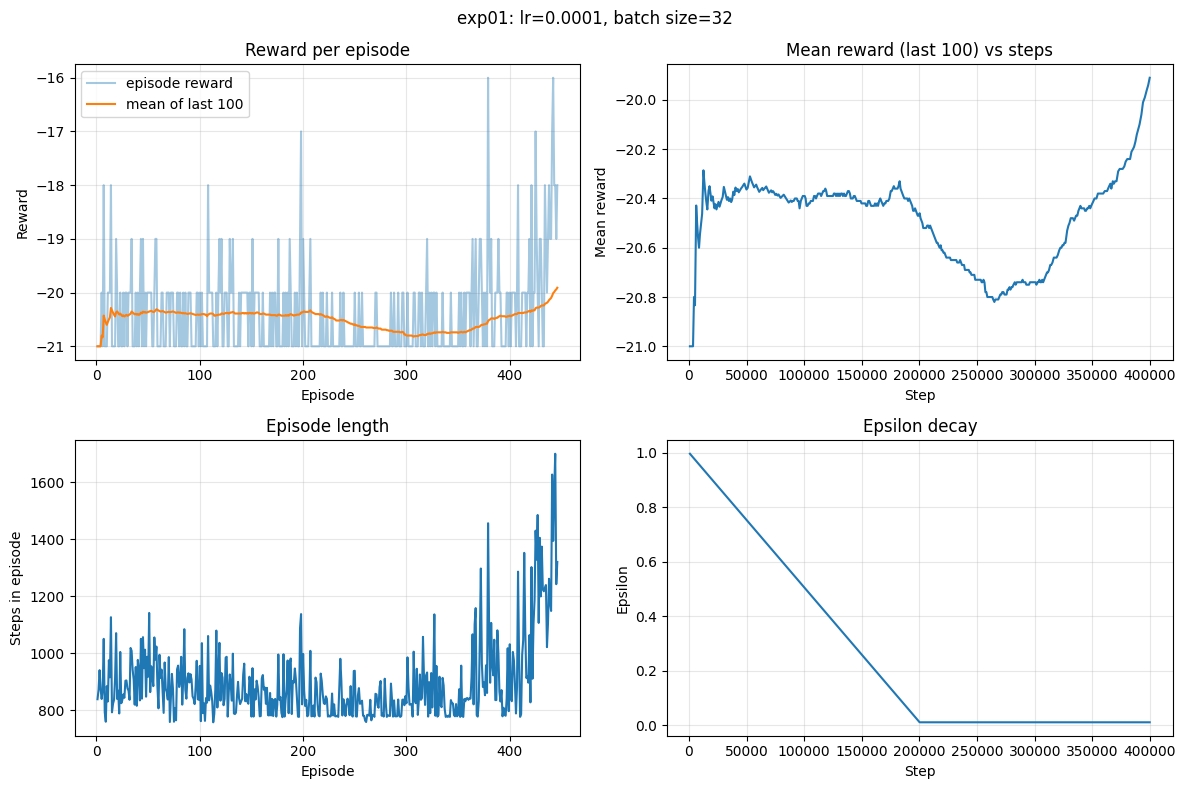

Episodes played: 446
Average reward of the last 100 episodes: -19.9
Best 100-episode average during training: -19.9


In [5]:
# Experiment 1: baseline, the group's default values
run_experiment("exp01", lr=1e-4, batch_size=32)

exp02 already has results, so it is not trained again.


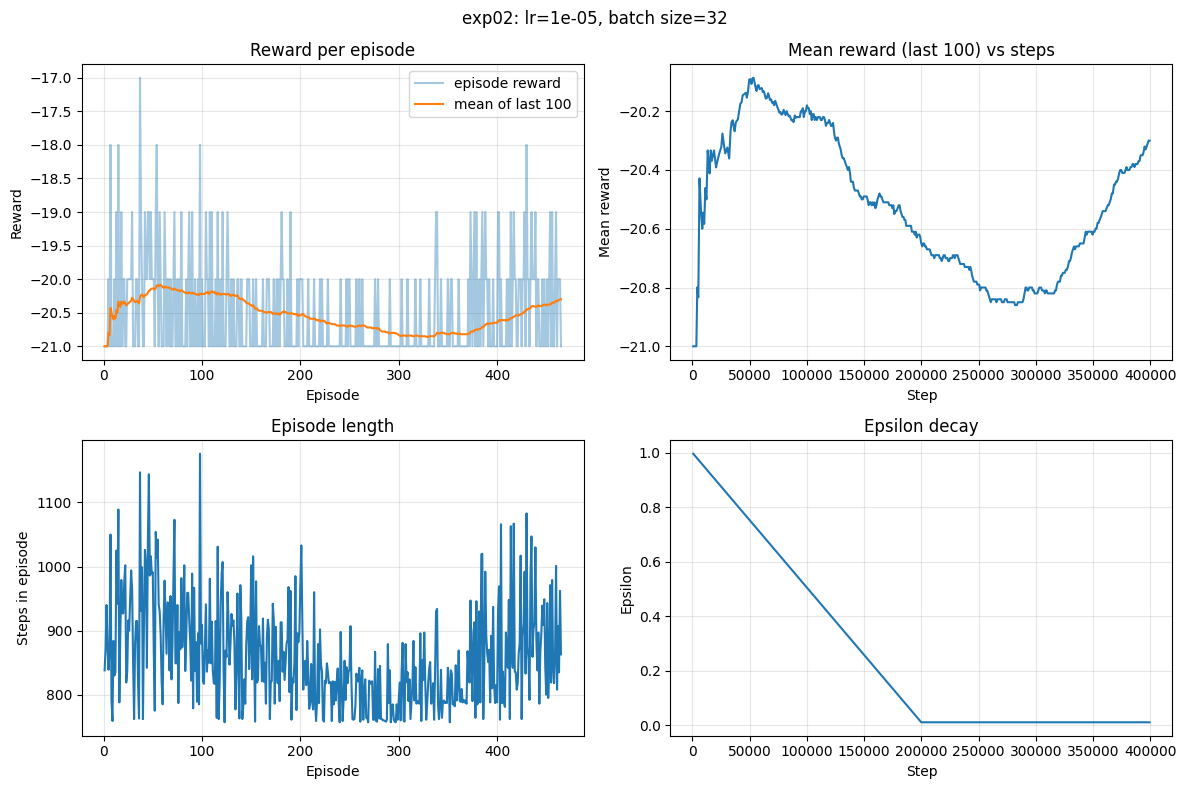

Episodes played: 465
Average reward of the last 100 episodes: -20.3
Best 100-episode average during training: -20.1


In [6]:
# Experiment 2: 10 times smaller than the baseline.
run_experiment("exp02", lr=1e-5, batch_size=32)

exp03 already has results, so it is not trained again.


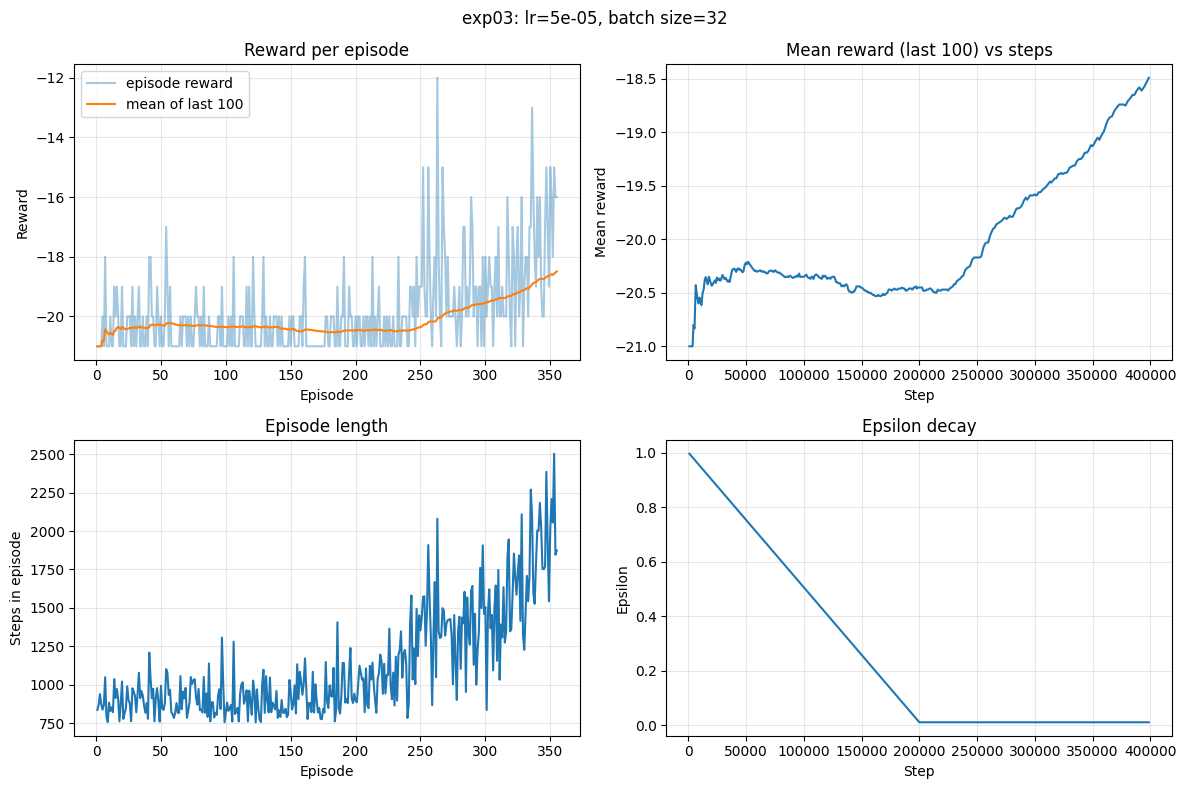

Episodes played: 355
Average reward of the last 100 episodes: -18.5
Best 100-episode average during training: -18.5


In [7]:
# Experiment 3: half the baseline
run_experiment("exp03", lr=5e-5, batch_size=32)

Running: uv run train.py --lr 0.00025 --batch-size 32 --out experiments/Alliane/exp04


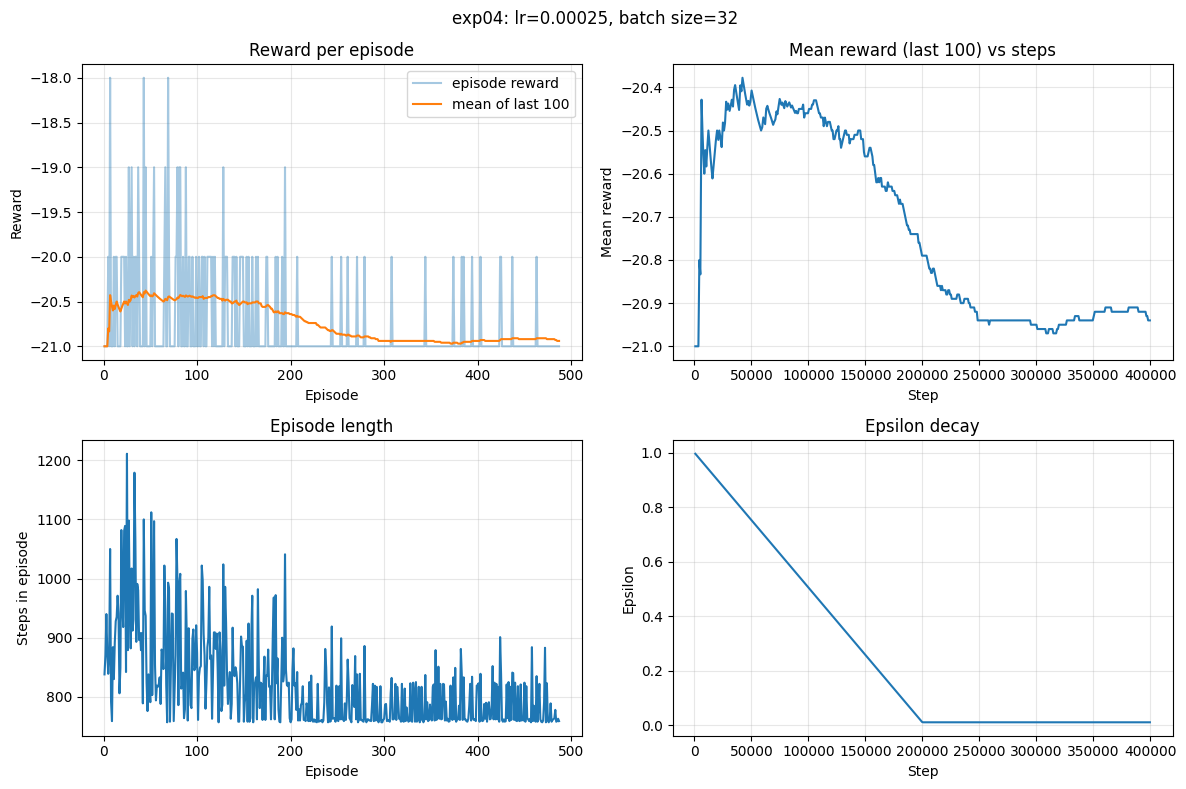

exp04 pushed to GitHub
Episodes played: 487
Average reward of the last 100 episodes: -20.9
Best 100-episode average during training: -20.4


In [8]:
# Experiment 4: 2.5e-4 is the learning rate used in the original DQN paper
run_experiment("exp04", lr=2.5e-4, batch_size=32)

Running: uv run train.py --lr 0.0005 --batch-size 32 --out experiments/Alliane/exp05


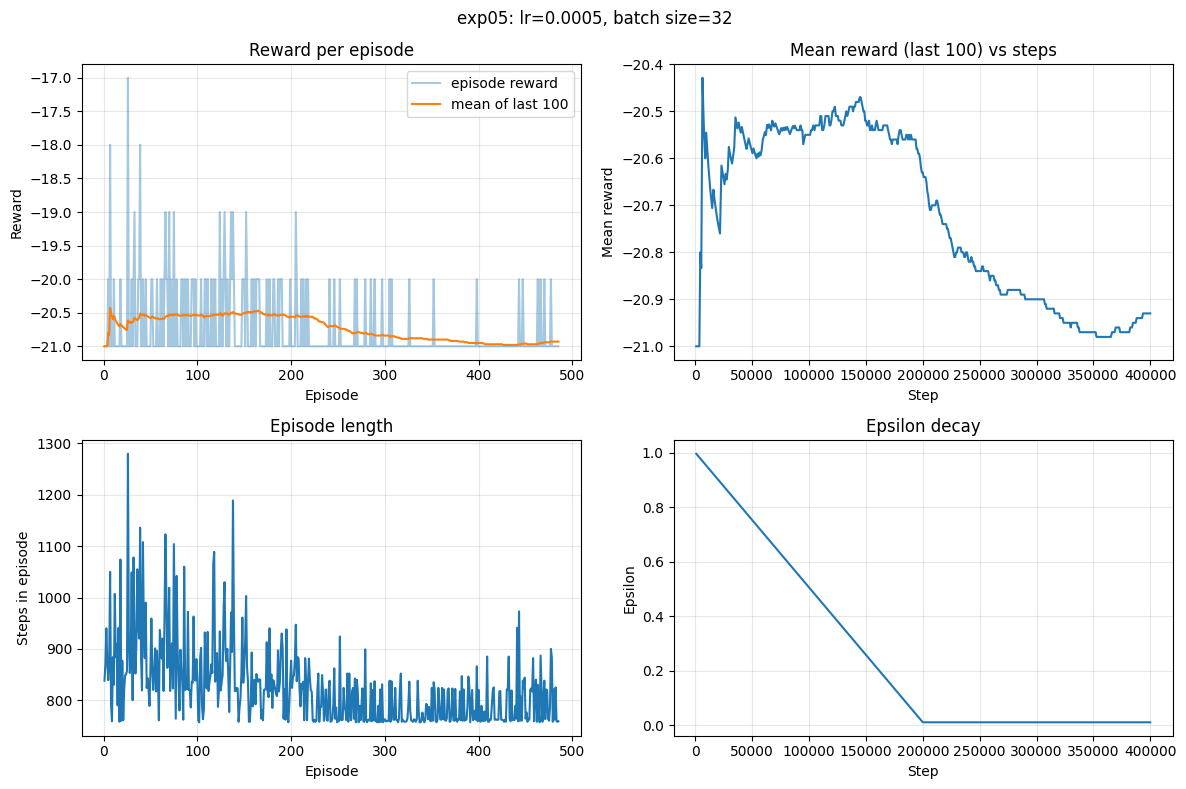

exp05 pushed to GitHub
Episodes played: 485
Average reward of the last 100 episodes: -20.9
Best 100-episode average during training: -20.4


In [9]:
# Experiment 5: 5 times the baseline. Faster learning, or the start of instability?
run_experiment("exp05", lr=5e-4, batch_size=32)

Running: uv run train.py --lr 0.001 --batch-size 32 --out experiments/Alliane/exp06


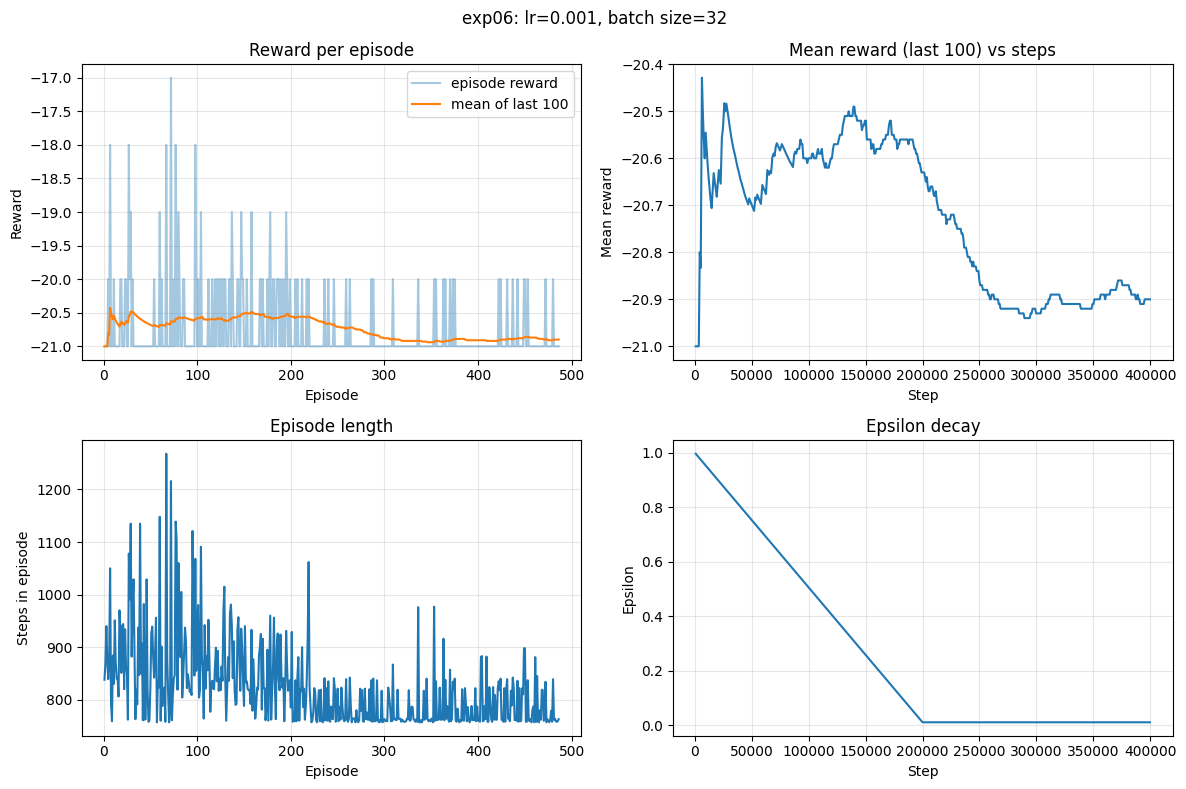

exp06 pushed to GitHub
Episodes played: 486
Average reward of the last 100 episodes: -20.9
Best 100-episode average during training: -20.4


In [10]:
# Experiment 6: 10 times the baseline. Expect unstable training:
# the loss jumps around and the reward may stop improving or get worse.
run_experiment("exp06", lr=1e-3, batch_size=32)

Running: uv run train.py --lr 0.0001 --batch-size 16 --out experiments/Alliane/exp07


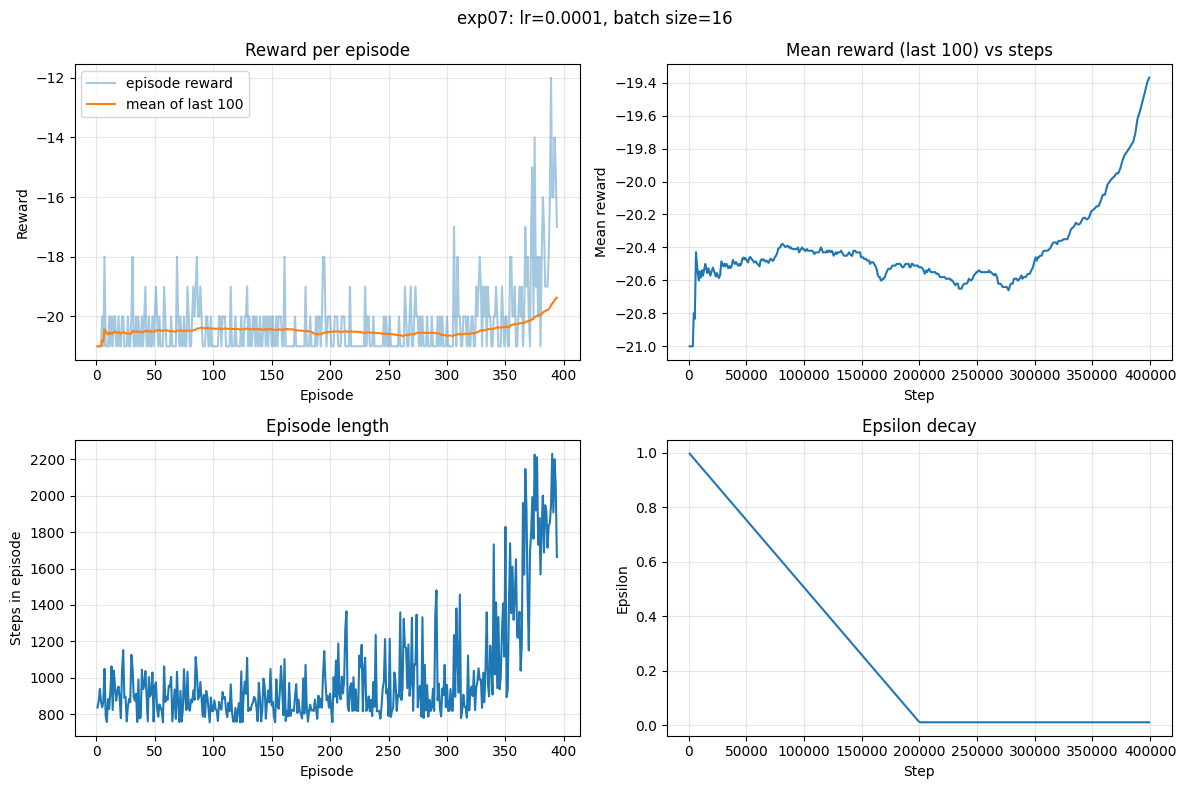

exp07 pushed to GitHub
Episodes played: 394
Average reward of the last 100 episodes: -19.4
Best 100-episode average during training: -19.4


In [11]:
# Experiment 7: half the baseline batch
run_experiment("exp07", lr=1e-4, batch_size=16)

Running: uv run train.py --lr 0.0001 --batch-size 64 --out experiments/Alliane/exp08


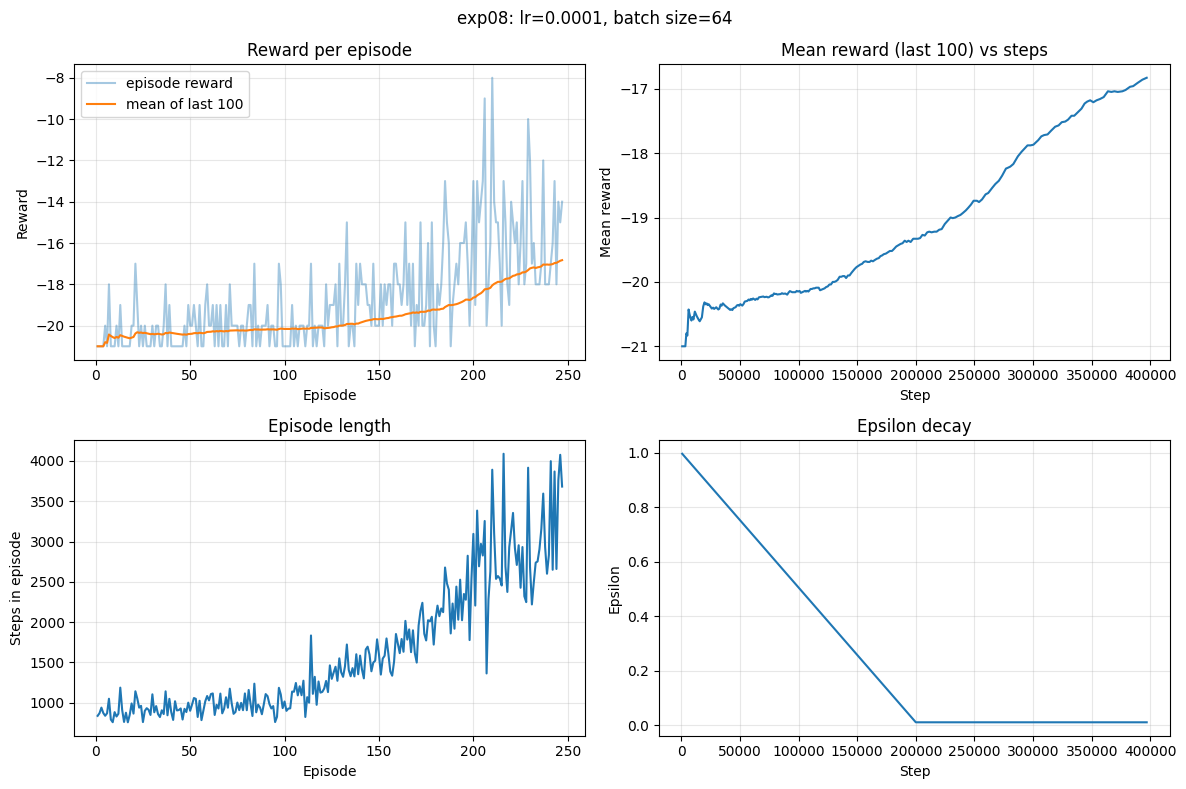

exp08 pushed to GitHub
Episodes played: 247
Average reward of the last 100 episodes: -16.8
Best 100-episode average during training: -16.8


In [12]:
# Experiment 8: double the baseline batch
run_experiment("exp08", lr=1e-4, batch_size=64)

Running: uv run train.py --lr 0.0001 --batch-size 128 --out experiments/Alliane/exp09


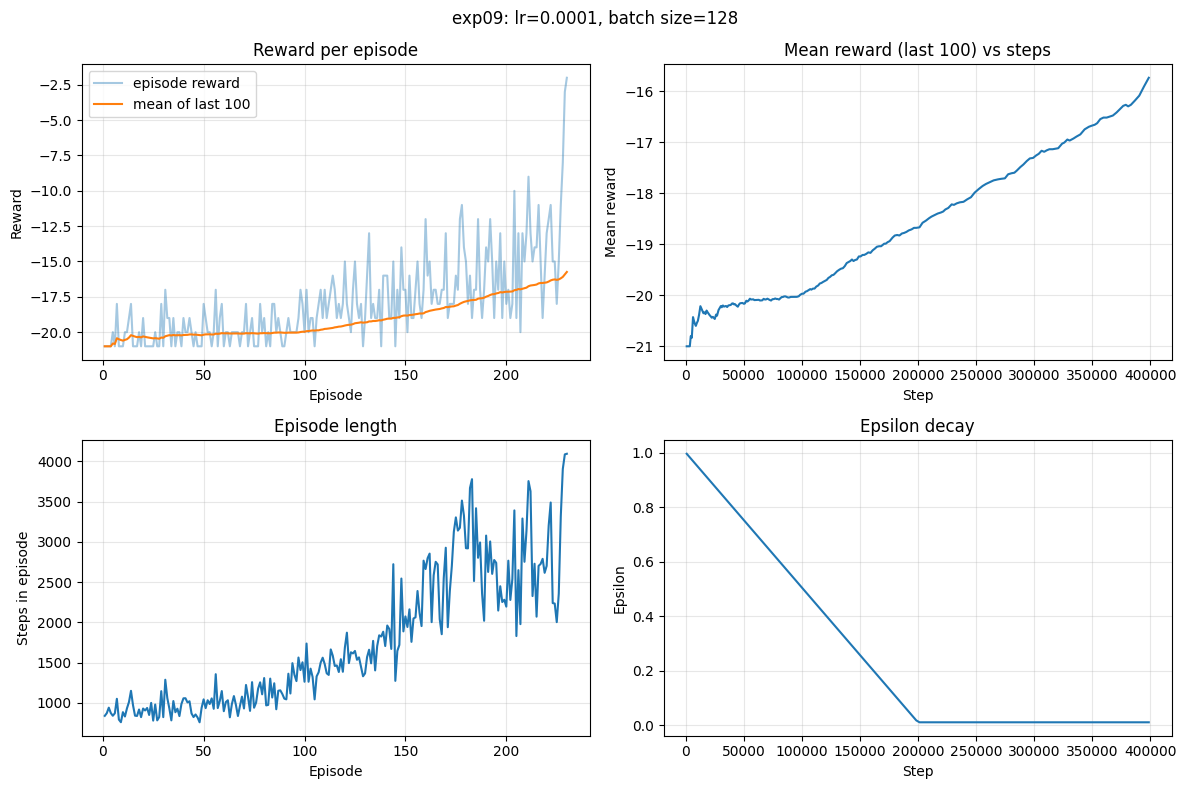

exp09 pushed to GitHub
Episodes played: 230
Average reward of the last 100 episodes: -15.7
Best 100-episode average during training: -15.7


In [13]:
# Experiment 9: four times the baseline batch
run_experiment("exp09", lr=1e-4, batch_size=128)

Running: uv run train.py --lr 0.00025 --batch-size 64 --out experiments/Alliane/exp10


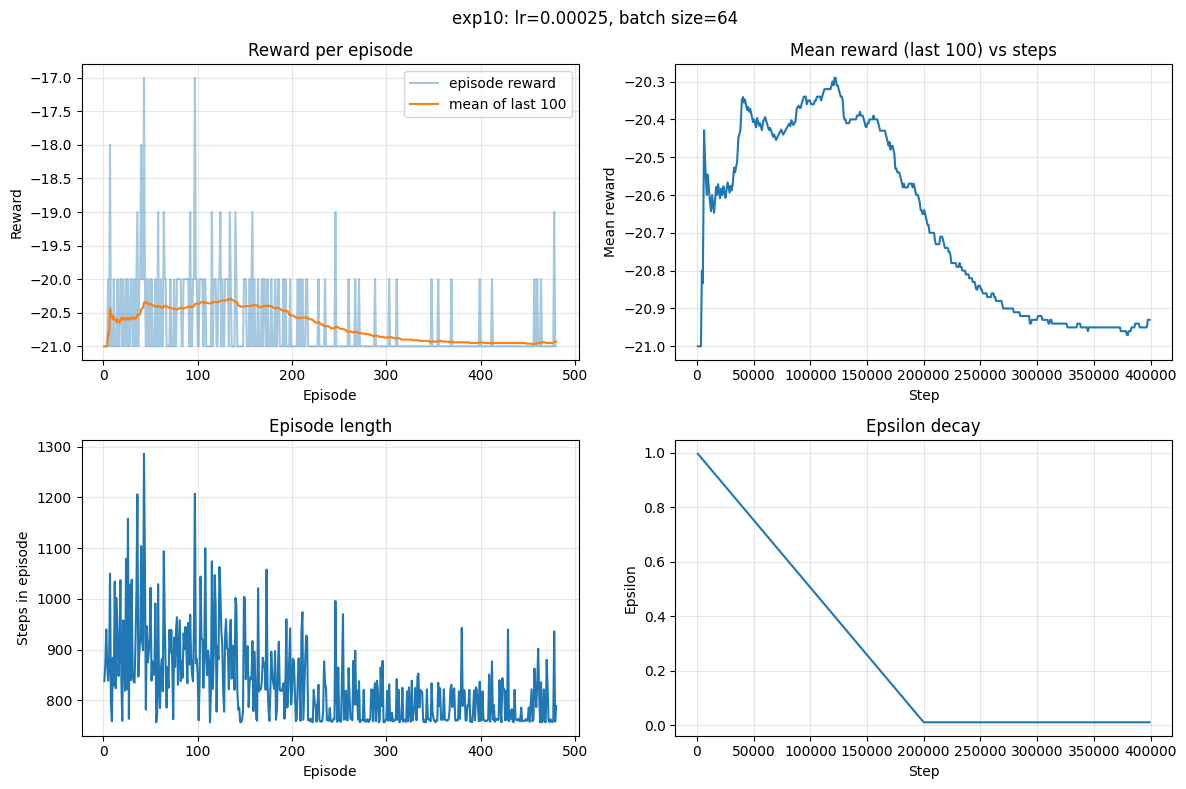

exp10 pushed to GitHub
Episodes played: 480
Average reward of the last 100 episodes: -20.9
Best 100-episode average during training: -20.3


In [14]:
# Experiment 10: a bigger batch gives a less noisy gradient, so it may handle
# a higher learning rate better than batch size 32 did in experiment 4
run_experiment("exp10", lr=2.5e-4, batch_size=64)

In [15]:
# One row per finished experiment
rows = []
for folder in sorted((ROOT / "experiments/Alliane").glob("exp*")):
    csv_path = folder / "log.csv"
    if not csv_path.exists():
        continue
    log = pd.read_csv(csv_path)
    mean_100 = log["reward"].rolling(100, min_periods=1).mean()
    rows.append({
        "experiment": folder.name,
        "episodes": len(log),
        "final 100-episode average": round(mean_100.iloc[-1], 1),
        "best 100-episode average": round(mean_100.max(), 1),
        "final loss": round(log["loss"].iloc[-1], 4),
    })

pd.DataFrame(rows)

,experiment,episodes,final 100-episode average,best 100-episode average,final loss
0,exp01,446,-19.9,-19.9,0.0085
1,exp02,465,-20.3,-20.1,0.0049
2,exp03,355,-18.5,-18.5,0.0024
3,exp04,487,-20.9,-20.4,0.0004
4,exp05,485,-20.9,-20.4,0.0004
5,exp06,486,-20.9,-20.4,0.0009
6,exp07,394,-19.4,-19.4,0.0014
7,exp08,247,-16.8,-16.8,0.0051
8,exp09,230,-15.7,-15.7,0.0023
9,exp10,480,-20.9,-20.3,0.0156
